![Estimer le prix des logements à Bordeaux Métropole](https://raw.githubusercontent.com/yayefatou-lam/prix-logements-bordeaux/main/assets/banner.png)

# Prix des logements à Bordeaux Métropole · 3. Modélisation

**Yaye Fatou Lam** · projet personnel de data science · notebook 3 sur 3

| $\color{#B5562F}{\mathbf{11{,}6\,\%}}$ | $\color{#B5562F}{\mathbf{630\,€}}$ | $\color{#B5562F}{\mathbf{44\,\%}}$ | $\color{#B5562F}{\mathbf{-23\,\%}}$ |
|:---:|:---:|:---:|:---:|
| erreur relative médiane sur 2025 | erreur moyenne par m² | des ventes estimées à ±10 % | d'erreur par rapport à la référence |

> $\color{#2F76AE}{\textbf{Sommaire}}$
>
> 1. Variables et découpage dans le temps
> 2. Comparer les modèles
> 3. Une variable de plus : le prix des voisins
> 4. Régler LightGBM
> 5. Évaluation finale sur 2025
> 6. Où le modèle se trompe
> 7. Ce que le modèle a appris (SHAP)
> 8. Fourchette de l'application

Objectif : prédire le **prix au m²** d'un logement à partir de ses caractéristiques et de sa position. La règle centrale : **le test 2025 n'est utilisé qu'une seule fois**, à la fin. Tous les choix (modèle, réglages, variables) se font sur la validation 2024.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# Racine du dépôt : les notebooks sont dans notebooks/
RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

from src.affichage import fr, tableau

import time
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt

from src.variables import construire_variables, sans_vides

warnings.filterwarnings("ignore", message="The argument 'eval_set' is deprecated")
ventes = pd.read_parquet(RACINE / "data" / "ventes_bm_2021_2025.parquet")

## $\color{#B5562F}{\mathbf{1}}$ &nbsp; Variables et découpage dans le temps

| Variable | Pourquoi |
|---|---|
| Type, surface, nombre de pièces | écart maisons / appartements, effet en U de la surface |
| Surface de terrain (maisons), dépendances | inclus dans le prix |
| Latitude, longitude, distance au centre | la localisation est le facteur principal |
| Mois depuis janvier 2021 | suivre l'évolution du marché |

Le **prix total** n'est pas une variable : ce serait donner la réponse au modèle (fuite de données). La **commune** est écartée, car redondante avec les coordonnées et fragile pour les petites communes.

In [2]:
X = construire_variables(ventes)
y = ventes["prix_m2"]
annee = ventes["date_mutation"].dt.year

# Test : 2025, jamais vu pendant l'entraînement
test = annee == 2025
X_train, X_test, y_train, y_test = X[~test], X[test], y[~test], y[test]

# Validation interne : apprentissage 2021-2023, validation 2024
fit, val = annee[~test] < 2024, annee[~test] == 2024
X_fit, X_val, y_fit, y_val = X_train[fit], X_train[val], y_train[fit], y_train[val]

print(f"Apprentissage 2021-2023 : {fr(len(X_fit))} · validation 2024 : {fr(len(X_val))} · test 2025 : {fr(len(X_test))}")
NOMS_VAR = {"maison": "Maison (0/1)", "surface": "Surface (m²)", "pieces": "Pièces",
            "surface_terrain": "Terrain (m²)", "nb_dependances": "Dépendances",
            "latitude": "Latitude", "longitude": "Longitude",
            "distance_centre_km": "Distance au centre (km)", "mois": "Mois depuis janv. 2021"}
tableau(X.describe()
         .rename(columns=NOMS_VAR)
         .rename(index={"count": "Nombre", "mean": "Moyenne", "std": "Écart-type", "min": "Minimum",
                        "25%": "1er quartile", "50%": "Médiane", "75%": "3e quartile", "max": "Maximum"}),
        decimales=1)

Apprentissage 2021-2023 : 36 717 · validation 2024 : 9 156 · test 2025 : 11 371


,Maison (0/1),Surface (m²),Pièces,Terrain (m²),Dépendances,Latitude,Longitude,Distance au centre (km),Mois depuis janv. 2021
Nombre,"57 244,0","57 244,0","57 244,0","20 267,0","57 244,0","57 244,0","57 244,0","57 244,0","57 244,0"
Moyenne,"0,4","74,2","3,2","512,9","0,8","44,8","-0,6","4,9","28,1"
Écart-type,"0,5","38,5","1,4","1 167,7","0,8","0,0","0,1","3,5","17,7"
Minimum,"0,0","9,0","1,0","3,0","0,0","44,8","-0,8","0,1","0,0"
1er quartile,"0,0","47,0","2,0","191,0","0,0","44,8","-0,6","2,3","13,0"
Médiane,"0,0","68,0","3,0","351,0","1,0","44,8","-0,6","4,1","26,0"
3e quartile,"1,0","92,0","4,0","597,0","1,0","44,9","-0,6","6,8","44,0"
Maximum,"1,0","550,0","15,0","42 946,0","5,0","45,0","-0,5","22,1","59,0"


> $\color{#8A6420}{\textbf{Point de vigilance}}$
>
> Un modèle à arbres ne sait pas prolonger une tendance : pour une vente de 2025, il raisonne comme pour une vente de fin 2024.
> Le marché ayant peu bougé entre 2024 et 2025, ce n'est pas bloquant, mais c'est une limite.

In [3]:
def evaluer(y_vrai, y_pred, nom):
    """Erreur moyenne (€/m²), erreur relative médiane et part des ventes estimées à ±10 %."""
    erreur_rel = (y_pred - y_vrai).abs() / y_vrai
    return pd.Series({
        "MAE (€/m²)": round((y_pred - y_vrai).abs().mean()),
        "Erreur relative médiane (%)": round(100 * erreur_rel.median(), 1),
        "Ventes à ±10 % (%)": round(100 * (erreur_rel <= 0.10).mean(), 1),
    }, name=nom)


# Décimales des tableaux de scores
DEC = {"Erreur relative médiane (%)": 1, "Ventes à ±10 % (%)": 1, "Durée (s)": 1}
REF = "Référence : médiane commune × type"


def reference(idx_appr, idx_pred):
    """Référence naïve : médiane du prix au m² par commune et par type, apprise sur idx_appr."""
    appr = ventes.loc[idx_appr]
    med = appr.groupby(["code_commune", "type_local"])["prix_m2"].median()
    cles = pd.MultiIndex.from_frame(ventes.loc[idx_pred, ["code_commune", "type_local"]])
    pred = pd.Series(med.reindex(cles).to_numpy(), index=idx_pred)
    med_type = appr.groupby("type_local")["prix_m2"].median()
    return pred.fillna(ventes.loc[idx_pred, "type_local"].map(med_type))

## $\color{#B5562F}{\mathbf{2}}$ &nbsp; Comparer les modèles

Du plus simple au plus complexe, avec des réglages fixés à l'avance et des budgets comparables pour les trois bibliothèques de gradient boosting. Tous les modèles prédisent le **logarithme** du prix au m², pour que les erreurs comptent en pourcentage plutôt qu'en euros.

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

params_lgb = dict(objective="regression", learning_rate=0.05, num_leaves=63, min_child_samples=30,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_estimators=600,
                  random_state=42, verbose=-1)

candidats = {
    "Régression linéaire (Ridge)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Plus proches voisins (k = 15)": make_pipeline(
        StandardScaler(), KNeighborsRegressor(n_neighbors=15, weights="distance")),
    "Forêt aléatoire": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "Réseau de neurones (MLP)": make_pipeline(
        StandardScaler(), MLPRegressor(hidden_layer_sizes=(128, 64), early_stopping=True,
                                       max_iter=300, random_state=42)),
    "LightGBM": lgb.LGBMRegressor(**params_lgb),
    "XGBoost": XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=8, subsample=0.8,
                            colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=42),
    "CatBoost": CatBoostRegressor(iterations=1000, learning_rate=0.05, depth=8, random_seed=42, verbose=0),
}

comparaison = [evaluer(y_val, reference(X_fit.index, X_val.index), "Référence : médiane commune × type")]
preds_val = {}
for nom, modele in candidats.items():
    debut = time.time()
    modele.fit(sans_vides(X_fit), np.log(y_fit))
    preds_val[nom] = modele.predict(sans_vides(X_val))
    ligne = evaluer(y_val, pd.Series(np.exp(preds_val[nom]), index=y_val.index), nom)
    ligne["Durée (s)"] = round(time.time() - debut, 1)
    comparaison.append(ligne)

# Ensemble : moyenne des trois modèles de boosting (en échelle log)
moy = np.mean([preds_val[n] for n in ["LightGBM", "XGBoost", "CatBoost"]], axis=0)
comparaison.append(evaluer(y_val, pd.Series(np.exp(moy), index=y_val.index),
                           "Ensemble (LightGBM + XGBoost + CatBoost)"))
comparaison = pd.DataFrame(comparaison)
meilleur = comparaison["MAE (€/m²)"].idxmin()
tableau(comparaison, ocre=[REF], sauge=[meilleur], decimales=DEC,
        legende="En ocre : le score à battre · en vert : la plus faible erreur moyenne sur 2024.")

,MAE (€/m²),Erreur relative médiane (%),Ventes à ±10 % (%),Durée (s)
Référence : médiane commune × type,836,"15,9","34,0",–
Régression linéaire (Ridge),818,"16,2","33,0","0,0"
Plus proches voisins (k = 15),744,"14,1","37,2","0,5"
Forêt aléatoire,670,"12,3","42,2","11,6"
Réseau de neurones (MLP),754,"15,0","34,5","19,2"
LightGBM,662,"12,3","41,6","2,0"
XGBoost,675,"12,6","40,8","1,5"
CatBoost,661,"12,3","41,7","3,8"
Ensemble (LightGBM + XGBoost + CatBoost),657,"12,2","41,9",–


> $\color{#55623F}{\textbf{Constat}}$
>
> La régression linéaire fait à peine mieux que la référence en erreur moyenne, et moins bien en erreur relative : les effets ne sont pas linéaires.
> Les plus proches voisins (l'approche « par comparables ») font mieux, le réseau de neurones déçoit.
> Les modèles à arbres sont au coude à coude : changer d'algorithme ne fait presque plus rien gagner. **On a atteint un plateau.**

## $\color{#B5562F}{\mathbf{3}}$ &nbsp; Une variable de plus : le prix des voisins

Pour franchir le plateau, on teste une variable classique en immobilier : le **prix médian au m² des 20 ventes les plus proches, du même type**. Pour éviter toute fuite, les voisins de la validation sont cherchés uniquement parmi les ventes 2021-2023, et une vente ne compte jamais parmi ses propres voisins.

In [5]:
from sklearn.neighbors import BallTree


def prix_voisins(ref, cible, k=20, exclure_soi=False):
    """Prix médian au m² des k ventes les plus proches de même type, cherchées dans ref."""
    resultat = pd.Series(np.nan, index=cible.index)
    for type_local in ["Appartement", "Maison"]:
        r = ref[ref["type_local"] == type_local]
        c = cible[cible["type_local"] == type_local]
        # Distance réelle sur la sphère terrestre (coordonnées en radians)
        arbre = BallTree(np.radians(r[["latitude", "longitude"]].to_numpy()), metric="haversine")
        _, idx = arbre.query(np.radians(c[["latitude", "longitude"]].to_numpy()), k=k + int(exclure_soi))
        if exclure_soi:
            # Retire la vente elle-même, même si d'autres ventes ont les mêmes coordonnées
            soi = np.arange(len(c))[:, None]
            idx = np.array([ligne[ligne != s[0]][:k] for ligne, s in zip(idx, soi)])
        resultat.loc[c.index] = np.median(r["prix_m2"].to_numpy()[idx], axis=1)
    return resultat


v_fit, v_val = ventes.loc[X_fit.index], ventes.loc[X_val.index]
X_fit2 = X_fit.assign(prix_voisins=prix_voisins(v_fit, v_fit, exclure_soi=True))
X_val2 = X_val.assign(prix_voisins=prix_voisins(v_fit, v_val))

comparaison2 = []
for nom in ["Forêt aléatoire", "LightGBM", "XGBoost", "CatBoost"]:
    modele = candidats[nom]
    modele.fit(sans_vides(X_fit2), np.log(y_fit))
    pred = pd.Series(np.exp(modele.predict(sans_vides(X_val2))), index=y_val.index)
    comparaison2.append(evaluer(y_val, pred, f"{nom} + prix des voisins"))
tableau(pd.DataFrame(comparaison2), decimales=DEC)

,MAE (€/m²),Erreur relative médiane (%),Ventes à ±10 % (%)
Forêt aléatoire + prix des voisins,677,"12,6","41,7"
LightGBM + prix des voisins,666,"12,5","41,7"
XGBoost + prix des voisins,677,"12,5","41,4"
CatBoost + prix des voisins,663,"12,4","42,0"


> $\color{#55623F}{\textbf{Constat}}$
>
> Aucun gain : l'information est **déjà captée par les coordonnées**, que les arbres découpent en petites zones.
> Argument pratique en plus : l'application devrait embarquer toutes les ventes DVF pour la calculer. La variable n'est pas gardée.

## $\color{#B5562F}{\mathbf{4}}$ &nbsp; Régler LightGBM

LightGBM est retenu : aussi bon que les autres, le plus rapide, et directement explicable avec SHAP. On tire **30 combinaisons de réglages au hasard** (recherche aléatoire), dont trois fonctions de perte : `regression` (carré de l'erreur), `regression_l1` (valeur absolue, qui vise la médiane) et `huber` (compromis). Classement sur la validation 2024.

In [6]:
rng = np.random.default_rng(42)
essais = []
for i in range(30):
    p = dict(
        objective=str(rng.choice(["regression", "regression_l1", "huber"])),
        num_leaves=int(rng.choice([15, 31, 63, 127, 255])),
        min_child_samples=int(rng.choice([10, 20, 30, 50, 100])),
        subsample=float(rng.choice([0.6, 0.8, 1.0])),
        colsample_bytree=float(rng.choice([0.6, 0.8, 1.0])),
        reg_lambda=float(rng.choice([0, 1, 5, 10])),
        learning_rate=0.03, subsample_freq=1, n_estimators=5000, random_state=42, verbose=-1,
    )
    m = lgb.LGBMRegressor(**p)
    m.fit(X_fit, np.log(y_fit), eval_set=[(X_val, np.log(y_val))], eval_metric="l1",
          callbacks=[lgb.early_stopping(200, verbose=False)])
    pred = pd.Series(np.exp(m.predict(X_val)), index=y_val.index)
    essais.append({**evaluer(y_val, pred, f"essai {i}"), "n_arbres": m.best_iteration_,
                   **{k: p[k] for k in ["objective", "num_leaves", "min_child_samples",
                                        "subsample", "colsample_bytree", "reg_lambda"]}})

essais = pd.DataFrame(essais).sort_values(["Erreur relative médiane (%)", "MAE (€/m²)"])
tableau(essais.head(5), decimales={**DEC, "subsample": 1, "colsample_bytree": 1})

,MAE (€/m²),Erreur relative médiane (%),Ventes à ±10 % (%),n_arbres,objective,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda
27,655,"11,9","43,3",2 089,regression_l1,63,30,"1,0","0,6",0
12,656,"12,0","43,3",3 658,regression_l1,15,50,"0,8","0,6",0
18,659,"12,0","42,8",1 495,regression_l1,127,20,"1,0","0,8",1
13,656,"12,1","43,4",936,regression_l1,127,100,"0,8","0,6",10
19,656,"12,1","43,1",1 378,regression_l1,63,10,"0,6","0,6",0


> $\color{#55623F}{\textbf{Constat}}$
>
> Les meilleurs essais utilisent tous `regression_l1` : c'est la fonction de perte qui fait la différence, logique pour un indicateur médian.
> Les écarts entre les premiers essais sont minimes. On retient le premier du classement ; ses réglages et son nombre d'arbres sont repris dans `src/entrainer.py`.

In [7]:
from src.entrainer import PARAMS

# Réglages retenus (identiques à ceux du script de production)
PARAMS

{'objective': 'regression_l1',
 'num_leaves': 63,
 'min_child_samples': 30,
 'subsample': 1.0,
 'colsample_bytree': 0.6,
 'reg_lambda': 0.0,
 'learning_rate': 0.03,
 'subsample_freq': 1,
 'n_estimators': 2089,
 'random_state': 42,
 'verbose': -1}

## $\color{#B5562F}{\mathbf{5}}$ &nbsp; Évaluation finale sur 2025

Tous les modèles sont réentraînés sur 2021-2024 avec les réglages fixés sur la validation, puis évalués **une seule fois** sur 2025.

In [8]:
candidats["LightGBM réglé"] = lgb.LGBMRegressor(**PARAMS)

final = [evaluer(y_test, reference(X_train.index, X_test.index), "Référence : médiane commune × type")]
preds_test = {}
for nom, modele in candidats.items():
    modele.fit(sans_vides(X_train), np.log(y_train))
    preds_test[nom] = modele.predict(sans_vides(X_test))
    final.append(evaluer(y_test, pd.Series(np.exp(preds_test[nom]), index=y_test.index), nom))

moy_t = np.mean([preds_test[n] for n in ["LightGBM", "XGBoost", "CatBoost"]], axis=0)
final.append(evaluer(y_test, pd.Series(np.exp(moy_t), index=y_test.index),
                     "Ensemble (LightGBM + XGBoost + CatBoost)"))
final = pd.DataFrame(final)
final.to_csv(RACINE / "assets" / "resultats_test_2025.csv")
tableau(final, ocre=[REF], sauge=["LightGBM réglé"], decimales=DEC,
        legende="En ocre : la référence · en vert : le modèle retenu. Test 2025, utilisé une seule fois.")

,MAE (€/m²),Erreur relative médiane (%),Ventes à ±10 % (%)
Référence : médiane commune × type,818,"15,9","34,3"
Régression linéaire (Ridge),765,"15,3","34,2"
Plus proches voisins (k = 15),712,"13,5","38,9"
Forêt aléatoire,637,"11,7","43,8"
Réseau de neurones (MLP),715,"14,1","36,7"
LightGBM,637,"11,8","43,7"
XGBoost,648,"12,0","43,4"
CatBoost,641,"11,9","43,0"
LightGBM réglé,630,"11,6","44,2"
Ensemble (LightGBM + XGBoost + CatBoost),636,"11,8","43,8"


> $\color{#55623F}{\textbf{Constat}}$
>
> Le **LightGBM réglé** arrive en tête sur les trois mesures : environ 630 €/m² d'erreur moyenne, 11,6 % d'erreur relative médiane, 44 % des ventes à ±10 %.
> Le classement observé sur 2024 se confirme sur 2025 : la sélection était saine.
> L'ensemble ne fait pas mieux que le LightGBM réglé seul : un modèle unique, plus simple, est justifié.

## $\color{#B5562F}{\mathbf{6}}$ &nbsp; Où le modèle se trompe

In [9]:
modele = candidats["LightGBM réglé"]
pred_lgb = pd.Series(np.exp(preds_test["LightGBM réglé"]), index=y_test.index)

analyse = ventes.loc[test, ["type_local"]].copy()
analyse["erreur_rel"] = (pred_lgb - y_test).abs() / y_test
analyse["ecart_signe"] = (pred_lgb - y_test) / y_test   # Positif : le modèle surestime
analyse["distance"] = pd.cut(X_test["distance_centre_km"], [0, 2, 5, 10, 25],
                             labels=["< 2 km", "2-5 km", "5-10 km", "> 10 km"])


def resume(par, nom):
    """Nombre de ventes, erreur médiane et biais médian (en %) par groupe."""
    return analyse.groupby(par, observed=True).agg(**{
        "Ventes": ("erreur_rel", "size"),
        "Erreur médiane (%)": ("erreur_rel", lambda s: 100 * s.median()),
        "Biais médian (%)": ("ecart_signe", lambda s: 100 * s.median()),
    }).rename_axis(nom)


biais = 100 * analyse["ecart_signe"].median()
print(f"Biais médian global : {'+' if biais >= 0 else '−'}{fr(abs(biais), 1)} %")
dec = {"Erreur médiane (%)": 1, "Biais médian (%)": 1}
display(tableau(resume("type_local", "Type"), decimales=dec))
display(tableau(resume("distance", "Distance au centre"), decimales=dec))

Biais médian global : +0,7 %


,Ventes,Erreur médiane (%),Biais médian (%)
Type,,,
Appartement,7 092,"10,6","1,4"
Maison,4 279,"13,2","-0,8"


,Ventes,Erreur médiane (%),Biais médian (%)
Distance au centre,,,
< 2 km,2 330,"15,0","1,7"
2-5 km,4 416,"11,8","0,1"
5-10 km,3 594,"10,1","1,0"
> 10 km,1 031,"10,9","0,4"


> $\color{#55623F}{\textbf{Constat}}$
>
> Le modèle ne penche ni vers le haut ni vers le bas en moyenne.
> Les maisons sont moins bien prédites que les appartements, et l'erreur est la plus forte près du centre.
> Hypothèse : l'état, l'étage, la vue ou la présence d'une piscine, absents de DVF, font varier les prix sans que le modèle puisse le voir.

## $\color{#B5562F}{\mathbf{7}}$ &nbsp; Ce que le modèle a appris (SHAP)

SHAP répartit chaque prédiction entre les variables. Comme le modèle prédit un logarithme, un effet de 0,1 correspond à environ ±10 % sur le prix au m². SHAP explique **le modèle**, pas le marché : il dit comment le modèle utilise chaque variable, pas qu'une variable *cause* le prix.

In [10]:
import shap

noms = {"distance_centre_km": "Distance au centre", "surface": "Surface", "mois": "Date de vente",
        "surface_terrain": "Surface du terrain", "maison": "Maison", "longitude": "Longitude",
        "latitude": "Latitude", "nb_dependances": "Dépendances", "pieces": "Pièces",
        "a_terrain": "A un terrain"}

echantillon = sans_vides(X_test).sample(min(3000, len(X_test)), random_state=42)
valeurs = shap.TreeExplainer(modele).shap_values(echantillon)

# Effet moyen de chaque variable, en pourcentage du prix au m²
effet = pd.Series(np.abs(valeurs).mean(axis=0), index=echantillon.columns).rename(index=noms)
tableau((100 * (np.exp(effet) - 1)).sort_values(ascending=False).rename("Effet moyen (%)"), decimales=1)

,Effet moyen (%)
Distance au centre,"10,6"
Date de vente,"7,5"
Surface,"7,0"
Surface du terrain,"6,2"
Maison,"4,9"
Longitude,"4,8"
Latitude,"3,6"
Pièces,"1,3"
Dépendances,"1,2"
A un terrain,"0,8"


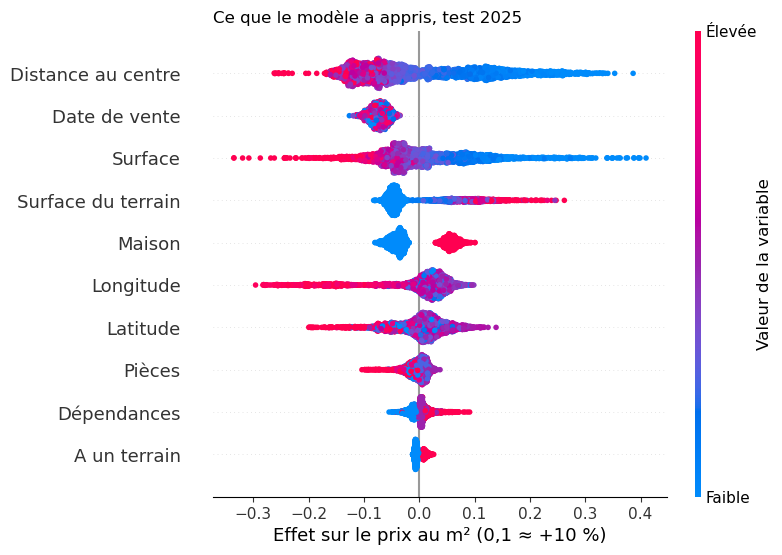

In [11]:
shap.summary_plot(valeurs, echantillon.rename(columns=noms), show=False)
fig = plt.gcf()
plt.xlabel("Effet sur le prix au m² (0,1 ≈ +10 %)")
barre = fig.axes[-1]
barre.set_yticklabels(["Faible", "Élevée"])
barre.set_ylabel("Valeur de la variable")
plt.title("Ce que le modèle a appris, test 2025", loc="left")
fig.savefig(RACINE / "assets" / "shap_resume.png", facecolor="white", dpi=150, bbox_inches="tight")
plt.show()

> $\color{#55623F}{\textbf{Constat}}$
>
> La **distance au centre** est la variable la plus influente, devant la date de vente (l'évolution du marché) et la surface.
> La **longitude** fait baisser le prix à l'est : le modèle a appris seul l'effet de la rive droite, sans qu'on trace la Garonne.
> Un grand terrain fait monter le prix des maisons, ce qui conforte l'hypothèse de l'exploration.

## $\color{#B5562F}{\mathbf{8}}$ &nbsp; Fourchette de l'application

L'application affiche une fourchette mesurée sur 2025 : on calcule pour chaque vente le rapport prix réel / prix prédit, et on regarde comment ces rapports se répartissent. Le modèle de l'application lui-même est produit par [`src/entrainer.py`](../src/entrainer.py), qui refait ce calcul et réentraîne sur 2021-2025.

In [12]:
ratio = y_test / pred_lgb
quantiles = {f"q{int(q * 100)}": round(float(ratio.quantile(q)), 3) for q in [0.10, 0.25, 0.75, 0.90]}
print(f"Une fois sur deux, le prix réel est entre {fr(100 * quantiles['q25'])} % et {fr(100 * quantiles['q75'])} % de l'estimation.")
print(f"Huit fois sur dix, entre {fr(100 * quantiles['q10'])} % et {fr(100 * quantiles['q90'])} %.")
quantiles

Une fois sur deux, le prix réel est entre 88 % et 111 % de l'estimation.
Huit fois sur dix, entre 76 % et 125 %.


{'q10': 0.758, 'q25': 0.88, 'q75': 1.11, 'q90': 1.252}